# 05 - Training

Training of the convolutional-recurrent classifier (`wqu.models.cred`) on one representation, with the parameters of
the `training` and `model` sections of `configs/default.yaml`:
- input standardized per frequency with mean and standard deviation of the training records;
- weighted BCE loss, bad-class weight `n_good / n_bad` of the training records;
- Adam, learning rate reduced on plateau of the validation loss, early stopping, best model kept;
- per-epoch history (loss, AUC, balanced accuracy, ECE, learning rate) and its figures;
- MC dropout predictions on the validation set.

Every run writes to its own folder `training.runs_dir/<representation>_<date>_<time>/`: copy of the configuration,
normalization statistics, `history.csv` (updated at every epoch), `best_model.pt`, figures and validation predictions.

The training metrics are computed on the outputs produced while training (dropout active, weights changing within the
epoch), the validation metrics on a deterministic pass at the end of the epoch: with strong dropout the training loss can
stay above the validation loss without any anomaly.

## 0. Setup

In [ ]:
from pathlib import Path

import pandas as pd

from wqu.config import load_config
from wqu.data.loading import CV_COMPONENTS
from wqu.data.splitting import SPLIT_COLUMN, TRAIN, VALIDATION, attach_split, load_split
from wqu.models.cred import build_model
from wqu.models.loss import bad_class_weight, weighted_bce_loss
from wqu.models.uncertainty import prediction_table
from wqu.preprocessing.pipeline import FEATURE_INDEX_COLUMN, feature_file_path, read_feature_records
from wqu.training.data import FeatureDataset, frequency_statistics, make_loader
from wqu.training.metrics import classification_metrics
from wqu.training.trainer import VALIDATION_PREDICTIONS_FILE, create_run_dir, fit, select_device, set_seed
from wqu.visualization import apply_plot_style, plot_training_curve, plot_training_history, save_figure
import matplotlib.pyplot as plt

CONFIG_PATH = Path("..") / "configs" / "default.yaml"

config = load_config(CONFIG_PATH)
columns = config.columns
training = config.training
apply_plot_style()
set_seed(training.random_seed)
device = select_device(training.device)

features_path = feature_file_path(config.preprocessing, training.feature_source)
records = read_feature_records(features_path, columns.text)
records[SPLIT_COLUMN] = attach_split(records, load_split(config.split.output_file, columns), columns)
print(f"Feature file: {features_path} ({len(records):,} records); representation: {training.representation}; "
      f"device: {device}")

/Users/giulianaparadiso/miniconda3/envs/wqu/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Feature file: /Users/giulianaparadiso/Desktop/Projects/waveform-quality-uncertainty/data/processed/dev_subset/features.h5 (2,000 records); representation: spectrogram; device: mps


## 1. Data

Per-frequency statistics from the training records only, bad-class weight from the training labels.

In [ ]:
train_records = records[records[SPLIT_COLUMN] == TRAIN]
validation_records = records[records[SPLIT_COLUMN] == VALIDATION]
statistics = frequency_statistics(features_path, training.representation, train_records[FEATURE_INDEX_COLUMN].to_numpy())
bad_weight = bad_class_weight(train_records[columns.label].to_numpy())

run_dir = create_run_dir(training.runs_dir, training.representation, CONFIG_PATH)
statistics.save(run_dir / "normalization.npz")


def loader_for(subset: pd.DataFrame, shuffle: bool):
    """Loader of standardized images for a subset of the records."""
    dataset = FeatureDataset(features_path, training.representation, subset[FEATURE_INDEX_COLUMN].to_numpy(),
                             subset[columns.label].to_numpy(), statistics)
    return make_loader(dataset, training.batch_size, shuffle, training.num_workers, training.random_seed)


train_loader = loader_for(train_records, shuffle=True)
validation_loader = loader_for(validation_records, shuffle=False)
summary = records.groupby(SPLIT_COLUMN)[columns.label].agg(records="size", bad_rate="mean")
print(f"Run folder: {run_dir}")
print(f"Bad-class weight: {bad_weight:.3f}")
summary.round(3)

Run folder: /Users/giulianaparadiso/Desktop/Projects/waveform-quality-uncertainty/runs/spectrogram_20261110_190126
Bad-class weight: 0.995


,records,bad_rate
split,,
train,1600,0.501
validation,400,0.495


## 2. Training

The progress is printed at every epoch; `history.csv` in the run folder is rewritten at every epoch, so the run can be
followed from outside the notebook.

In [ ]:
model = build_model(config.model, len(CV_COMPONENTS), len(statistics.mean))
result = fit(model, train_loader, validation_loader, weighted_bce_loss(bad_weight), training, bad_weight, run_dir, device)
history = result.history
print(f"Best epoch: {result.best_epoch} of {len(history)}; stopped early: {result.stopped_early}; "
      f"total time {history['seconds'].sum() / 60:.1f} min")
history.round(4)

epoch   1  train loss 0.6496  validation loss 0.5688  validation AUC 0.8144  lr 1.0e-03  3 s  (best)
epoch   2  train loss 0.5300  validation loss 0.5028  validation AUC 0.8379  lr 1.0e-03  2 s  (best)
epoch   3  train loss 0.4901  validation loss 0.5576  validation AUC 0.8435  lr 1.0e-03  2 s
epoch   4  train loss 0.4897  validation loss 0.4913  validation AUC 0.8486  lr 1.0e-03  2 s  (best)
epoch   5  train loss 0.4667  validation loss 0.4871  validation AUC 0.8526  lr 1.0e-03  2 s  (best)
epoch   6  train loss 0.4567  validation loss 0.4771  validation AUC 0.8598  lr 1.0e-03  2 s  (best)
epoch   7  train loss 0.4555  validation loss 0.4829  validation AUC 0.8544  lr 1.0e-03  2 s
epoch   8  train loss 0.4519  validation loss 0.4724  validation AUC 0.8663  lr 1.0e-03  2 s  (best)
epoch   9  train loss 0.4378  validation loss 0.4693  validation AUC 0.8593  lr 1.0e-03  2 s  (best)
epoch  10  train loss 0.4283  validation loss 0.4455  validation AUC 0.8718  lr 1.0e-03  2 s  (best)
epoch 

,epoch,learning_rate,train_loss,validation_loss,train_auc,train_balanced_accuracy,train_ece,validation_auc,validation_balanced_accuracy,validation_ece,seconds
0,1,0.0010,0.6496,0.5688,0.6770,0.6272,0.0457,0.8144,0.7032,0.1129,2.8199
1,2,0.0010,0.5300,0.5028,0.8149,0.7551,0.0391,0.8379,0.7669,0.0726,1.7475
2,3,0.0010,0.4901,0.5576,0.8422,0.7738,0.0222,0.8435,0.7154,0.1472,1.7419
3,4,0.0010,0.4897,0.4913,0.8426,0.7758,0.0382,0.8486,0.7844,0.0641,1.7197
4,5,0.0010,0.4667,0.4871,0.8584,0.7895,0.0313,0.8526,0.7992,0.0754,1.7002
5,6,0.0010,0.4567,0.4771,0.8638,0.7901,0.0311,0.8598,0.7869,0.0625,1.6830
6,7,0.0010,0.4555,0.4829,0.8646,0.7957,0.0300,0.8544,0.7667,0.0722,1.6834
7,8,0.0010,0.4519,0.4724,0.8676,0.8001,0.0243,0.8663,0.7938,0.0819,1.6758
8,9,0.0010,0.4378,0.4693,0.8771,0.8032,0.0247,0.8593,0.7891,0.0484,1.6485
9,10,0.0010,0.4283,0.4455,0.8825,0.8070,0.0294,0.8718,0.8122,0.0630,1.5812


## 3. Training curves

Overview (loss and learning rate on top; AUC, balanced accuracy and ECE below) and the loss alone. The dashed line marks
the epoch of the saved model.

PosixPath('/Users/giulianaparadiso/Desktop/Projects/waveform-quality-uncertainty/runs/spectrogram_20261110_190126/figures/training_loss.pdf')

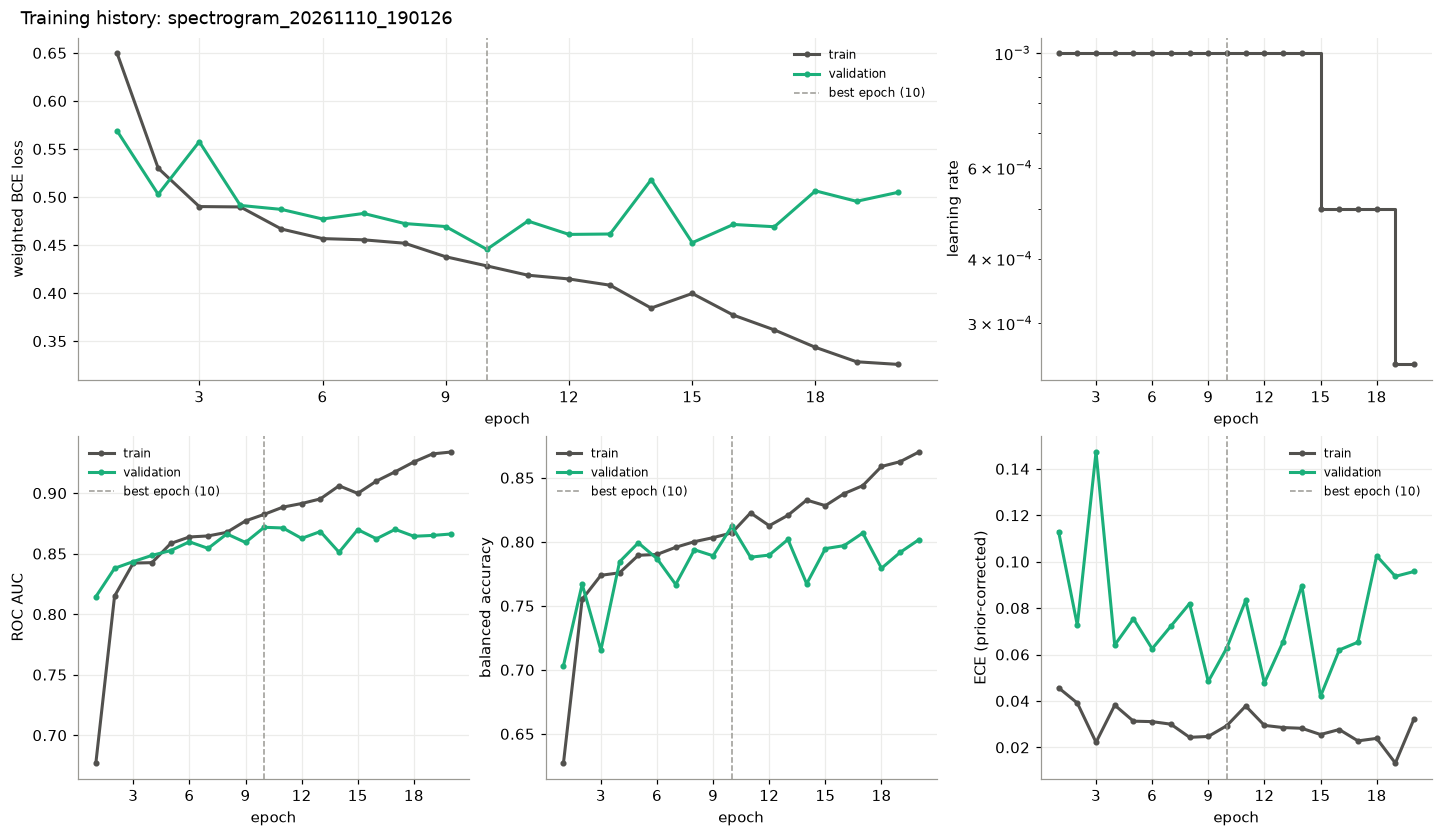

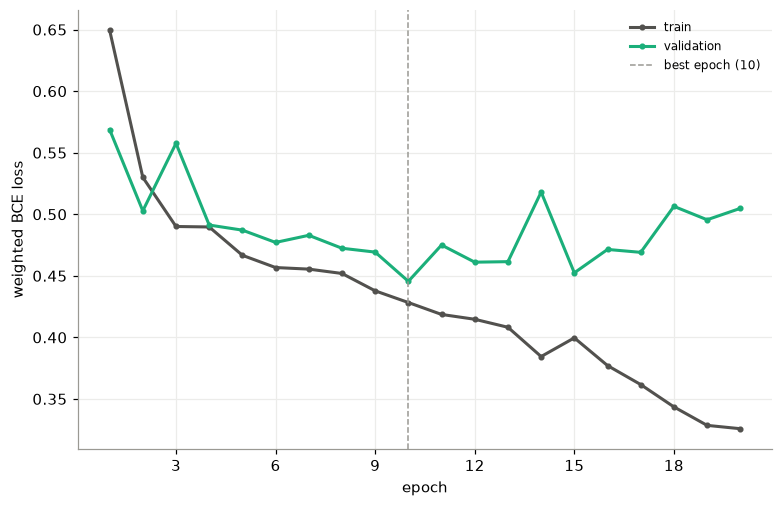

In [ ]:
figures_dir = run_dir / "figures"
overview = plot_training_history(history, result.best_epoch, f"Training history: {run_dir.name}")
save_figure(overview, figures_dir / "training_history.png")
save_figure(overview, figures_dir / "training_history.pdf")

loss_figure, loss_ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
plot_training_curve(history, "loss", result.best_epoch, loss_ax)
save_figure(loss_figure, figures_dir / "training_loss.png")
save_figure(loss_figure, figures_dir / "training_loss.pdf")

## 4. Validation predictions with MC dropout

For every validation record: probability of the bad class from the deterministic pass (dropout off) and its entropy;
from `model.mc_samples` stochastic passes, mean and standard deviation of the probability, predictive entropy and its
split into aleatoric part and mutual information (epistemic part); both probabilities also corrected to the class
frequencies of the training set. The table is the input of notebook 06 (evaluation).

In [ ]:
predictions = prediction_table(model, validation_loader, config.model.mc_samples, device, bad_weight)
predictions.insert(0, "record", validation_records.index.to_numpy())
predictions.insert(1, columns.label, validation_records[columns.label].to_numpy())
predictions.to_csv(run_dir / VALIDATION_PREDICTIONS_FILE, index=False)

labels = predictions[columns.label].to_numpy()
comparison = {}
for name, probability in (("deterministic", "probability_deterministic"), ("mc_dropout", "probability_mean")):
    metrics = classification_metrics(predictions[probability].to_numpy(), labels, training.calibration_bins)
    metrics["ece"] = classification_metrics(predictions[f"{probability}_corrected"].to_numpy(), labels,
                                            training.calibration_bins)["ece"]
    comparison[name] = metrics
comparison = pd.DataFrame(comparison)
comparison.to_csv(run_dir / "validation_metrics.csv")
comparison.round(4)

,deterministic,mc_dropout
auc,0.8718,0.8755
balanced_accuracy,0.8122,0.8172
ece,0.0630,0.0621


In [ ]:
predictions.groupby(columns.label)[["probability_mean", "probability_std", "predictive_entropy",
                                     "mutual_information"]].describe().T.round(4)

label                            0         1
probability_mean   count  202.0000  198.0000
                   mean     0.2936    0.7036
                   std      0.2136    0.2486
                   min      0.0421    0.1012
                   25%      0.1323    0.5299
                   50%      0.2216    0.8024
                   75%      0.4065    0.9122
                   max      0.9454    0.9710
probability_std    count  202.0000  198.0000
                   mean     0.0665    0.0625
                   std      0.0240    0.0261
                   min      0.0293    0.0241
                   25%      0.0510    0.0443
                   50%      0.0611    0.0553
                   75%      0.0750    0.0725
                   max      0.1837    0.1857
predictive_entropy count  202.0000  198.0000
                   mean     0.4954    0.4562
                   std      0.1495    0.1751
                   min      0.1746    0.1312
                   25%      0.3789    0.2974
                   50%      0.5138    0.4488
                   75%      0.6331    0.6373
                   max      0.6931    0.6931
mutual_information count  202.0000  198.0000
                   mean     0.0150    0.0146
                   std      0.0091    0.0090
                   min      0.0041    0.0034
                   25%      0.0102    0.0101
                   50%      0.0130    0.0126
                   75%      0.0168    0.0162
                   max      0.0731    0.0741